In [5]:
''' getting important libraries which is used 
    during identifying chokepoint and 
    chronically delayed corridors(CDC)
    we implemented to tried to convert our Sourcehubs
    and Destination hubs as nodes for which we used
    networkx and matplotlib to visualize
    and rank top 5 chokepoints/(CDC)
    pandas to manage dataframe and numpy for fast computatuion'''
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

In [9]:
#saving df to reference our delhivery data cleanied
df = pd.read_csv('delhivery_cleaned_1.csv')

In [10]:
'''since our dataset already has
    segment factor thats why we deleting our 
    segment ratio to reduce feature redundancy'''
del df['segment_factor']

KeyError: 'segment_ratio'

In [ ]:
#getting the list of our columns
df.columns

In [11]:
'''getting a set of  unique destination center
   getting a set of  unique source center 
   we first applied unique() to get unique list of dst_center then applied set()
   to get a set of destination_hubs,source_hubs
   then since source_hubs,destination_hubs are set 
   we get the union of both of them
   to get a set of unique nodes
   and then we printed total number of nodes,
   total number of  source_hubs,destination_hubs
'''
destination_hubs = set(df['destination_center'].unique())
source_hubs = set(df['source_center'].unique())
nodes = destination_hubs.union(source_hubs)
print(f'Number of nodes are:-{len(nodes)},\nNumber of Source hub:-\t{len(source_hubs)},\nNumber of dest hub:-\t{len(destination_hubs)}')

Number of nodes are:-1657,
Number of Source hub:-	1508,
Number of dest hub:-	1481


In [12]:
''' since we have to capture weights of the 
    edges using the median actual-vs-OSRM we
    first groupby our data using source_name,destination name 
    then we applied aggregation function of median to both
    ratio of segment_factor and median of base_distance
    we reset index to 0,1,2,3,4.... for our data in row wise'''
network_edge = df.groupby(['source_name','destination_name']).agg(
    median_ratio = ('segment_factor','median'),
    base_distance = ('segment_osrm_distance','median')
).reset_index()

In [13]:
''' we printed our network 
    edge dataframe to see how our network edge information
    looks like'''
network_edge

,source_name,destination_name,median_ratio,base_distance
0,AMD_Memnagar (Gujarat),AMD_Memnagar (Gujarat),2.000000,11.40050
1,AMD_Satellite (Gujarat),AMD_Satellite (Gujarat),2.222222,10.62235
2,Abohar_DC (Punjab),Abohar_DC (Punjab),1.717391,22.80520
3,Achrol_BgwriDPP_D (Rajasthan),Achrol_BgwriDPP_D (Rajasthan),1.500000,23.51295
4,Addanki_Oilmilrd_D (Andhra Pradesh),Addanki_Oilmilrd_D (Andhra Pradesh),1.306250,21.59575
...,...,...,...,...
1486,Zahirabad_Mohim_D (Telangana),Zahirabad_Mohim_D (Telangana),1.662500,34.39990
1487,Zirakpur_DC (Punjab),Zirakpur_DC (Punjab),1.166667,9.79660
1488,hubIND221010AAA,hubIND221005A1A,4.166667,13.12010
1489,hubIND331022A1B,hubIND331001A1C,3.250000,25.72460


In [14]:
#creating an object of directed graph
'''we then created a directed graph 
   and then we use iteration to fill our Graph edges 
   with the weight using network_edge data frame and G.add_edge()
   which we have created earlier we gave it information 
   source_name and destination_name 
   then we printed total number of edges and number of nodes'''
G=nx.DiGraph()
for index,row in network_edge.iterrows():
    G.add_edge(
        row['source_name'],
        row['destination_name'],
        weight = row['median_ratio'],
        distance = row['base_distance']        
    )
print(f'Number of Edges:-\t{G.number_of_edges()}')
print(f'Number of nodes:-\t{G.number_of_nodes()}')

Number of Edges:-	1491
Number of nodes:-	1475


In [15]:
'''we finally checked which sourcename and
    destination name is currently null 
    then we created a set of hubs removing all null in source_name and 
    destination_name since it is containing null previously'''
print("Missing Source Names:", df['source_name'].isna().sum())
print("Missing Destination Names:", df['destination_name'].isna().sum())
all_hubs = set(df['source_name'].dropna().unique()).union(set(df['destination_name'].dropna().unique()))
print(f'Absolute Hubs are:-{len(all_hubs)}')

Missing Source Names: 0
Missing Destination Names: 0
Absolute Hubs are:-1475


In [16]:
#printing nulls in our column
df.isnull().sum()

data                                  0
trip_creation_time                    0
route_schedule_uuid                   0
route_type                            0
trip_uuid                             0
source_center                         0
source_name                           0
destination_center                    0
destination_name                      0
od_start_time                         0
od_end_time                           0
start_scan_to_end_scan                0
is_cutoff                             0
cutoff_factor                         0
cutoff_timestamp                      0
actual_distance_to_destination        0
actual_time                           0
osrm_time                             0
osrm_distance                         0
factor                                0
segment_actual_time                   0
segment_osrm_time                     0
segment_osrm_distance                 0
segment_factor                        0
log_segment_factor                    0


In [17]:
''' DEFINITION OF 
    INDEGEE: In-Degree: The number of incoming edges a node receives. 
    A high in-degree often indicates popularity, 
    trust, or being a target of information.
    OUTDEGREE:  The number of edges originating from a node directed toward others. 
    A high out-degree suggests active communication or a broadcasting role.
    getting the dictionary of 
    metrics of our graph
    in_degree and out degree of 
    our nodes'''
print('Analyzing the network structure')
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

Analyzing the network structure


In [18]:
''''DEFINITION:
    BETWEENESS CENTRALITY:It calculates the percentage of the shortest paths
    between all node pairs in a network that pass through a specific node
    CLUSTERING COEFFICIENT:It is the ratio of 
    existing edges between a node's neighbors 
    to the maximum possible number of edges that
    could exist between those neighbors.
    --------------------------------------------
    calculating the 
    betweness centrality and clustering_coeff 
    then we created the metrics dictionary and made it as
    DATAFRAME and then we saved it as graph_metrics.csv file 
    index for not creating new column with 0,1,2,3,4....
    '''
betweeness = nx.betweenness_centrality(G,weight='weight')
clustering_coeff = nx.clustering(G)
metrics_df = pd.DataFrame({
    'Hub_name': list(G.nodes()),
    'In_degree':[in_degree[node] for node in G.nodes()],
    'Out_degree':[out_degree[node] for node in G.nodes()],
    'betweeness_centraility':[betweeness[node] for node in G.nodes()],
    'Clustering_coeff': [clustering_coeff[node] for node in G.nodes()]
    })
metrics_df.to_csv('graph_metrics.csv',index=False)

In [ ]:
''' we tried to print distinct values 
    which are presented in in degree,
    out degree, in centralit and clustering coefficient
print(f'Distinct in degree:-\t\t{metrics_df['In_degree'].unique()}\nDistinct out degree:-\t\t{metrics_df['Out_degree'].unique()}\nDistinct in centraility:-\t{metrics_df['betweeness_centraility'].unique()}\ndistinct  clustering_coeff:\t{metrics_df['Clustering_coeff'].unique()}')

In [19]:
''' we then counted our
    frequency of 0,1,2,3,4,5,6 
    for in and out degree'''
in_degree_distribution = metrics_df['In_degree'].value_counts()
out_degree_distribution = metrics_df['Out_degree'].value_counts()
print('Indegree_distribution')
print(in_degree_distribution)
print('out_degree_distribution')
print(out_degree_distribution)

Indegree_distribution
In_degree
1    1463
2       4
0       3
4       2
3       2
6       1
Name: count, dtype: int64
out_degree_distribution
Out_degree
1    1453
2      16
0       4
3       2
Name: count, dtype: int64


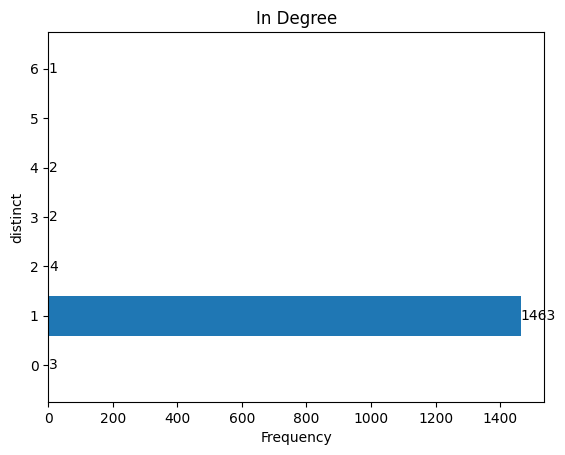

In [20]:
'''we tried to create a compartive
    bar graph of our distinct value counts for indegree'''
my_bar_in = plt.barh([1,2,0,4,3,6],in_degree_distribution)
plt.xlabel('Frequency')
plt.ylabel('distinct')
plt.title('In Degree')
plt.bar_label(my_bar_in)
plt.show()

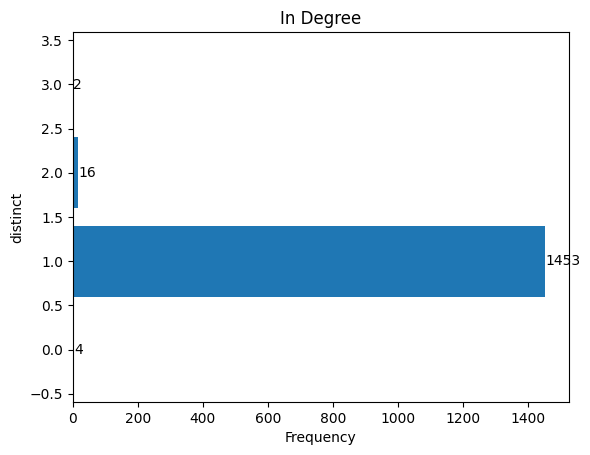

In [21]:
'''we tried to create a compartive
    bar graph of our distinct value counts for out-degree'''
my_bars = plt.barh([1,2,0,3],out_degree_distribution)
plt.xlabel('Frequency')
plt.ylabel('distinct')
plt.title('In Degree')
plt.bar_label(my_bars)
plt.show()

In [22]:
''' we are now tried to classify segment based on the 
    factor that critical chokepoint hubs and chronically 
    delayed corridors (actual time exceeds OSRM by >20%)
    we then tried to sum total chokepoints in our dataset and we flagged them
    '''
df['chokepoint_flag'] = np.where(df['segment_factor'] > 1.20,1,0)
total_chokepoints = df['chokepoint_flag'].sum()
print(f'Total Chronically Delayed Segments Identified:{total_chokepoints}')


Total Chronically Delayed Segments Identified:120178


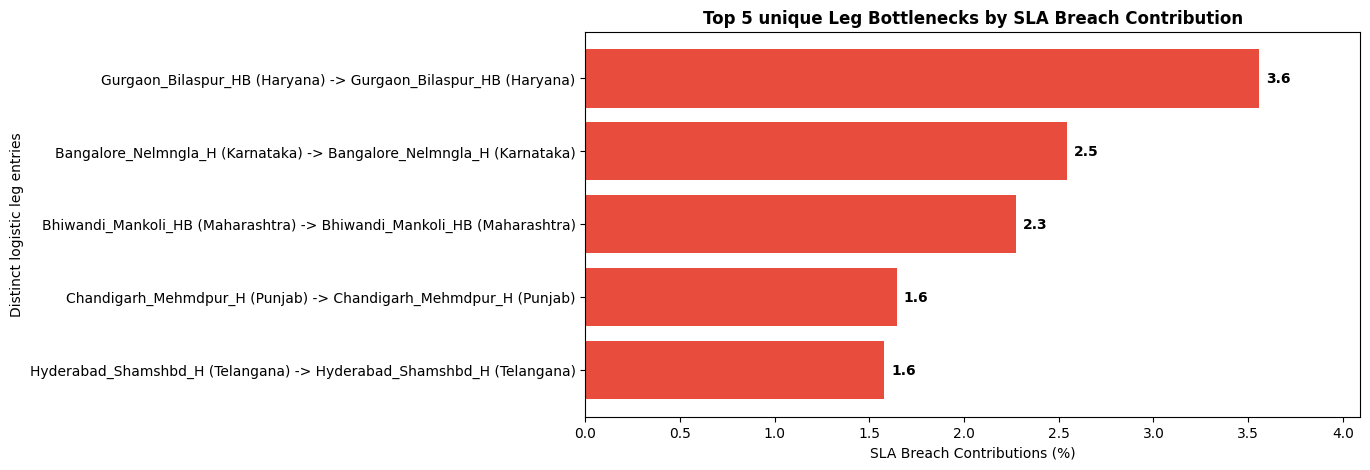

In [23]:
''' we first created a sorted list in (max-to-min) based on segment
    factor then from the sorted list we drop the duplicate based on
    looking only at the subset subset=['trip_uuid','segment_name'])
    we then groupby ou data based on segment name then we applied an 
    aggregation function of sum() to count total choke point happend 
    because of that segment then we calculated total chokepoint breaches
    then since we have created a DF known as segment_breaches we created 
    its new column AKA 'breach_contribution_% which is equal to 
    segment_breaches['chokepoint_flag']/total_network_breaches which means
    total chokes by that segment divided by total choke point then we converted
    it into %
    '''
df_sorted = df.sort_values(by='segment_factor',ascending=False)
df_unique_segments = df_sorted.drop_duplicates(subset=['trip_uuid','segment_name'])
segment_breaches = df_unique_segments.groupby('segment_name')['chokepoint_flag'].sum().reset_index()
total_network_breaches = segment_breaches['chokepoint_flag'].sum()
segment_breaches['breach_contribution_%']=(
    segment_breaches['chokepoint_flag']/total_network_breaches
)*100
''' we filterd top offender for chokepoint hubs and chronically delayed corridors(CDC)
    with the helo of breach_contribution then we sorted them based on column 
    breach_contribution_% and then we saved it as top_5_offenders
'''
top_5_offenders = segment_breaches.sort_values(
    by='breach_contribution_%',
    ascending=False).head(5)
top_5_offenders = top_5_offenders.iloc[::-1]
''' we then created a compartive bar plot and then 
    on the basis on breach_contribution_% we arranged
    them in descending order
    we described our bar graph features'''
plt.figure(figsize=(10,5))
my_breach_bars = plt.barh(
    top_5_offenders['segment_name'],
    top_5_offenders['breach_contribution_%'],
    color='#E74C3C'
)
''' then we give title xlabel , y-label, bar label fmt to format decimal
    then we saved our this cleaned dataset to and saved the fig to our root folder
'''
plt.xlabel('SLA Breach Contributions (%)')
plt.ylabel('Distinct logistic leg entries')
plt.title('Top 5 unique Leg Bottlenecks by SLA Breach Contribution',fontweight='bold')
plt.bar_label(my_breach_bars,padding=5,fmt='%.1f',fontweight='bold')
plt.xlim(0,max(top_5_offenders['breach_contribution_%'])*1.15)
plt.savefig('Top5_segment_Bottle_necks_plot.png',dpi=300,bbox_inches='tight')
plt.show()
df.to_csv('delihvery_cleaned_with_chokes.csv',index=False)

In [25]:
import networkx as nx

# Assuming 'G' is your directed graph representing the Delhivery logistics network
# Filter nodes where the number of incoming edges (in-degree) is strictly greater than 4
hubs_high_indegree = [node for node, in_deg in G.in_degree() if in_deg > 3]

print(f"Total hubs with in-degree > 4: {len(hubs_high_indegree)}")
print("Hub IDs/Names:", hubs_high_indegree)

Total hubs with in-degree > 4: 3
Hub IDs/Names: ['Gwalior_HrihrNgr_I (Madhya Pradesh)', 'Chikmagalur_DC (Karnataka)', 'Purnia_Central_H_2 (Bihar)']


In [30]:
import networkx as nx

# Assuming 'G' is your directed graph representing the Delhivery logistics network
# Filter nodes where the number of outgoing edges (out-degree) is strictly greater than 4
hubs_high_outdegree = [node for node, out_deg in G.out_degree() if out_deg > 2]

print(f"Total hubs with out-degree > 2: {len(hubs_high_outdegree)}")
print("Hub IDs/Names:", hubs_high_outdegree)

Total hubs with out-degree > 2: 2
Hub IDs/Names: ['Bangalore_Nelmngla_H (Karnataka)', 'Delhi_North_R_8 (Delhi)']


In [32]:
import networkx as nx

# Assuming 'G' is your directed graph representing the Delhivery logistics network
# Calculate betweenness centrality for all nodes (normalized=True by default)
betweenness_dict = nx.betweenness_centrality(G, normalized=True)

# Example 1: Filter hubs with a betweenness centrality greater than a specific threshold (e.g., > 0.05)
hubs_high_betweenness = [node for node, score in betweenness_dict.items() if score > 0.02]

print(f"Total hubs with Betweenness Centrality > 0.05: {len(hubs_high_betweenness)}")
print("Hub IDs/Names:", hubs_high_betweenness)

# Example 2: Sort and get the Top 10 critical bottleneck hubs in the network
top_10_bottlenecks = sorted(betweenness_dict.items(), key=lambda x: x[1], reverse=True)[:10]

print("\nTop 10 Bottleneck Hubs by Betweenness Centrality:")
for node, score in top_10_bottlenecks:
    print(f"Hub: {node} | Score: {score:.4f}")

Total hubs with Betweenness Centrality > 0.05: 0
Hub IDs/Names: []

Top 10 Bottleneck Hubs by Betweenness Centrality:
Hub: AMD_Memnagar (Gujarat) | Score: 0.0000
Hub: AMD_Satellite (Gujarat) | Score: 0.0000
Hub: Abohar_DC (Punjab) | Score: 0.0000
Hub: Achrol_BgwriDPP_D (Rajasthan) | Score: 0.0000
Hub: Addanki_Oilmilrd_D (Andhra Pradesh) | Score: 0.0000
Hub: Adoor_Town_D (Kerala) | Score: 0.0000
Hub: Agartala_Chmpmura_I (Tripura) | Score: 0.0000
Hub: Agra (Uttar Pradesh) | Score: 0.0000
Hub: Agra_Idgah_L (Uttar Pradesh) | Score: 0.0000
Hub: Agra_Idgah_P (Uttar Pradesh) | Score: 0.0000


In [33]:
import networkx as nx

# 1. Check if the graph is directed and pass your weight attribute (e.g., 'segment_factor' or 'weight')
# If your edge weight attribute is named something else, replace 'weight' with that name.
betweenness_dict = nx.betweenness_centrality(G, weight='weight', normalized=True)

# 2. Sort to find the actual highest values (even if they are small decimals)
top_10_bottlenecks = sorted(betweenness_dict.items(), key=lambda x: x[1], reverse=True)[:10]

print("Top 10 Bottleneck Hubs by Betweenness Centrality:")
for node, score in top_10_bottlenecks:
    print(f"Hub: {node} | Score: {score:.6f}")

Top 10 Bottleneck Hubs by Betweenness Centrality:
Hub: AMD_Memnagar (Gujarat) | Score: 0.000000
Hub: AMD_Satellite (Gujarat) | Score: 0.000000
Hub: Abohar_DC (Punjab) | Score: 0.000000
Hub: Achrol_BgwriDPP_D (Rajasthan) | Score: 0.000000
Hub: Addanki_Oilmilrd_D (Andhra Pradesh) | Score: 0.000000
Hub: Adoor_Town_D (Kerala) | Score: 0.000000
Hub: Agartala_Chmpmura_I (Tripura) | Score: 0.000000
Hub: Agra (Uttar Pradesh) | Score: 0.000000
Hub: Agra_Idgah_L (Uttar Pradesh) | Score: 0.000000
Hub: Agra_Idgah_P (Uttar Pradesh) | Score: 0.000000
